# NB Pipeline explanatory notebooks
## Notebook 2: Negative Binomial Model

The statistical model chosen to model clonotype counts is the Negative Binomial Distribution. In this notebook we will justify the choice of this distribution as well as the corrections made to it using biological considerations that arose in the EDA phase of section 1. We validate the model using simulations.

The objectgive of the pipeline is to determine which patient clonotypes are non-neutral. This is done by testing them agains a **null model** or **null hypothesis**, which we establish using **healthy donors**. In the literature, the most common way to establish a **null model** is using technical replicates from which the sampling noise can be determined, allowing to distinghish what is biological non-neutrality. Why use donors instead of replicates?
* `Resource/Funding contrains`: Technical replicates are expensive and not always a viable option due to resource limiation, as is our case. This would put our pipeline is a graceful spot with respect to other T-cell dynamics methdologies. All RNA-seq based methods rely on technical replicates for noise estiamtion, and even though some of them give the option to perfor analysis without them, they do specificallyt adress the propblems that arise from not using them. Our pipeline does adress them.
* `Bilological considerations`: There is also a biological argument to not use technical replicates (**REFERENCE**), or rather, to use healthy donors. Tehcnical replicates come from the patients own samples, which are expected to have more uderlying non-neutrality than a healthy person. During the computation of the sample noise, part of the genuine biology happening in the clonotype trajectotries can get confounded with technical noise, obscuring the detection of neutral clonotypes. By using healthy donors as the null baseline, we are asking a fundamentally different question for the null: How do healthy T-cell dynamics look like? 

### Summary of the choices made in this notebook

| Ingredient | Choice | Section |
|---|---|---|
| Null donors | the four 1M-PBMC donors (HDBR01, 02, 03, 06); HD106 / HD197 (3M PBMC) only for comparison | 2.0 |
| Offset | $L_t = D_t \times s_t$, size factors from abundant shared clones (not TMM) | 2.2 |
| Count model | negative binomial with dispersion $\phi$ | 2.3 |
| $\phi$ estimation | truncated likelihood + Cox–Reid, clones above a frequency floor of $10^{-5}$ | 2.4, 2.5 |
| $\phi$ vs frequency | estimated per donor; reference = pointwise minimum over the null donors | 2.6 |
| Missing timepoints and very low counts | not used as evidence of change: truncated test, counts below $k = 3$ not trusted | 2.7 |
| Validation | leave-one-donor-out on the null donors | 2.8 |

In [1]:
import sys
sys.path.insert(0, '..')

import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from tcr_pipeline.normalization import tmm_normalize
from tcr_pipeline.data_io import list_subjects, load_group, load_subject, sample_qc, drop_failed_samples
from tcr_pipeline import nb_glm as nb
from tcr_pipeline import nb_checks as chk

warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
RESULTS = Path('nb_results'); RESULTS.mkdir(exist_ok=True)

DONOR_COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300']
GREY, INK = '#8a8984', '#3d3c39'
plt.rcParams.update({
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.6,
    'axes.edgecolor': GREY, 'axes.labelcolor': INK, 'xtick.color': '#52514e',
    'ytick.color': '#52514e', 'lines.linewidth': 1.6, 'lines.markersize': 5,
    'legend.frameon': False, 'font.size': 9.5, 'axes.titlesize': 10})
short = chk.short

## 2.0 The donors: which ones define the null

The six healthy donors were not sequenced from the same amount of material:

* **HD106, HD197**: 3 million PBMC per sample.
* **HDBR01, HDBR02, HDBR03, HDBR06**: 1 million PBMC per sample, the amount used for the
  patients. (The HDBR data are the providers' second, correct shipment; the first batch
  was discarded.)

The input sets how many cells, and so how many TCR molecules, each sample captures.
Reads are amplified copies of those molecules, so with less input a clone of a given
frequency rests on fewer molecules: it is missed more often and its counts are noisier.
This is visible throughout the notebook (HD donors: higher $\phi$, about half the missed
clones). Since the null must describe the noise of a patient sample, **the null is built
from the four 1M-PBMC donors only**. HD106 and HD197 are fitted alongside, for comparison.

#### Warning: the full donor table is large in memory

In [2]:
healthy_raw = load_group('donors', with_D_t=True, with_freq=True)
d_qc = drop_failed_samples(healthy_raw, sample_qc(healthy_raw))
d_qc = tmm_normalize(d_qc)                    # TMM kept only for the comparison in 2.2
d_qc = nb.attach_size_factor_offset(d_qc)     # lib = D_t * size factor

DONORS = sorted(d_qc['patient'].unique())
NULL_DONORS = [p for p in DONORS if p.startswith('HDBR')]   # 1M PBMC, as the patients
COMPARE_DONORS = [p for p in DONORS if p not in NULL_DONORS] # 3M PBMC
COLOR = dict(zip(DONORS, DONOR_COLORS))
print(len(d_qc), 'rows,', d_qc.groupby(['patient', 'day'], observed=True).ngroups, 'samples')
print('null donors:', [short(p) for p in NULL_DONORS],
      '| comparison only:', [short(p) for p in COMPARE_DONORS])

13836210 rows, 23 samples
null donors: ['HDBR01', 'HDBR02', 'HDBR03', 'HDBR06'] | comparison only: ['HD106', 'HD197']


## 2.1 The model

For clone $c$ in sample $t$ of one person, the read count is

$$x_{ct} \sim \mathrm{NB}\!\left(\mu_{ct},\ \phi\right), \qquad
\log\mu_{ct} = \log L_t\ + \log\lambda_c + \beta_c s_t, \qquad s_t = \frac{t-\bar{t}}{t_{last} - t_{first}},\qquad
\mathrm{Var}(x_{ct}) = \mu_{ct} + \frac{\mu_{ct}^2}{\phi}.$$

* $\lambda_c$ is the clone's frequency. Under the **null** it is the same in every
  sample: the clone neither expands nor contracts.
* $L_t = D_t \times s_t$ is the sample's **offset**: its in-frame depth $D_t$
  (Section 1.1) times a size factor $s_t$ computed within the person (Section 2.2), so that
  $\mu_{ct}$ is the expected count of a clone of frequency $\lambda_c$ in that sample.
* $\phi$ is the **dispersion**. The NB is a Poisson whose mean is itself multiplied by
  a random factor with mean 1 and squared coefficient of variation $1/\phi$. This dispersion (sometimes called overdispersion) encapsulates
  sample-to-sample noise of library preparation, RNA content per cell, amplification.
  Small $\phi$ means noisy, $\phi \to \infty$ is a Poisson (only pure sampling noise).
* $\beta_c$: the clone’s trajectory. $s_t$ is time rescaled to run over one unit across the series, so $\beta_c$ is the log fold change from the first sample to the last. For example,   $\beta_c = \log 10$ is a 10-fold expansion over the series and $\beta_c = -\log 10$ a 10-fold contraction

This is a GLM per clone: a log link, an offset, two coefficients ($\alpha_c$, $\beta_c$) and a dispersion fixed in advance.

**The null hypothesis** $H_0: \beta_c = 0$, but the meaning of “neutral” is set by the donors. Their $\phi$ is estimated with $\beta_c = 0$ for every clone, so any fluctuation healthy clones show, technical or biological, is absorbed into $\phi$. A patient clone is therefore called non-neutral when it changes more than clones in healthy people do, not merely when it is not constant. The healthy donors are assumed neutral, so $\phi$ is estimated under the null model, $\log\mu_{ct} = \log L_t + \alpha_c$, with only $\alpha_c$ fitted per clone. If a donor clone does change, the null model reads its change as extra noise and lowers $\phi$, the conservative direction. The full model with $\beta_c$ is only fitted when patients are tested.

## 2.2 Normalisation: size factors instead of TMM

For a neutral clone, all change between samples must come from the offset $L_t$. If
$L_t$ is wrong for one sample, **every** clone appears to move at that sample, and the
test reads one shared shift as thousands of changes, all in the same direction.

$D_t$ alone is right only if the composition of the libraries is comparable. A small
correction $s_t$ handles the rest, computed per person by the *median of ratios*
(as in DESeq2):

1. Reference clones: detected in **every** sample of the person, pooled frequency $\ge 10^{-5}$.
2. For each reference clone, its frequency in each sample relative to its own geometric
   mean across the person's samples, $\log(F_{ct}/\bar F_c)$, with $F_{ct} = x_{ct}/D_t$.
3. $s_t$ = exp(median over reference clones), rescaled to geometric mean 1 per person.

The median over thousands of abundant clones is robust to a minority of clones that really
change, and rare clones, whose counts depend strongly on depth and capture, are not used.

**Why not TMM.** On the raw tables ($c = 1$) TMM is computed over a pool dominated by rare
clones near the detection limit, and it mis-normalised whole samples by up to ~30%. The
clearest case is HDBR03 day 0 (twice the depth of its other samples): TMM gave 0.72 where
the abundant clones say ~1.0. In the leave-one-donor-out test (Section 2.8) this alone made
93% of HDBR03's false calls contractions and its error rate 8%; dropping day 0 brought it
to 1.7%, and size factors to 5.2%.

In [3]:
sf = nb.size_factors(d_qc).assign(patient=lambda x: x['patient'].astype(str))
tmm = (d_qc.groupby(['patient', 'day'], observed=True)['tmm_factor'].first().reset_index()
         .assign(patient=lambda x: x['patient'].astype(str)))
offsets = sf.merge(tmm, on=['patient', 'day'])
offsets['tmm_rescaled'] = offsets.groupby('patient')['tmm_factor'].transform(
    lambda s: s / np.exp(np.log(s).mean()))          # same scaling as the size factors
offsets['tmm_vs_sf'] = offsets['tmm_rescaled'] / offsets['size_factor']
display(offsets.assign(patient=offsets['patient'].map(short))
        [['patient', 'day', 'D_t', 'n_ref_clones', 'size_factor', 'tmm_rescaled', 'tmm_vs_sf']]
        .round(3))

,patient,day,D_t,n_ref_clones,size_factor,tmm_rescaled,tmm_vs_sf
0,HD106,0,21258772.0,4535,0.789,0.847,1.073
1,HD106,46,20765301.0,4535,1.149,1.022,0.889
2,HD106,82,13524147.0,4535,0.974,1.118,1.148
3,HD106,131,17575872.0,4535,1.132,1.034,0.913
4,HD197,0,16537619.0,5833,0.899,0.947,1.053
5,HD197,46,15524871.0,5833,1.123,1.015,0.904
6,HD197,82,18141316.0,5833,1.002,1.015,1.013
7,HD197,131,18289621.0,5833,0.989,1.025,1.037
8,HDBR01,0,10380249.0,3318,1.048,1.230,1.174
9,HDBR01,21,13135420.0,3318,1.013,0.981,0.969


## 2.3 Why NB instead of Poisson?
The reason of using NB over a simpler Poisson model is the count noise is not only due to pure samplign noise, but there are other external factors that need to be taken into consideration through the dispersion $\phi$. Next, we will investigate and justify this claim using the donor data itself.

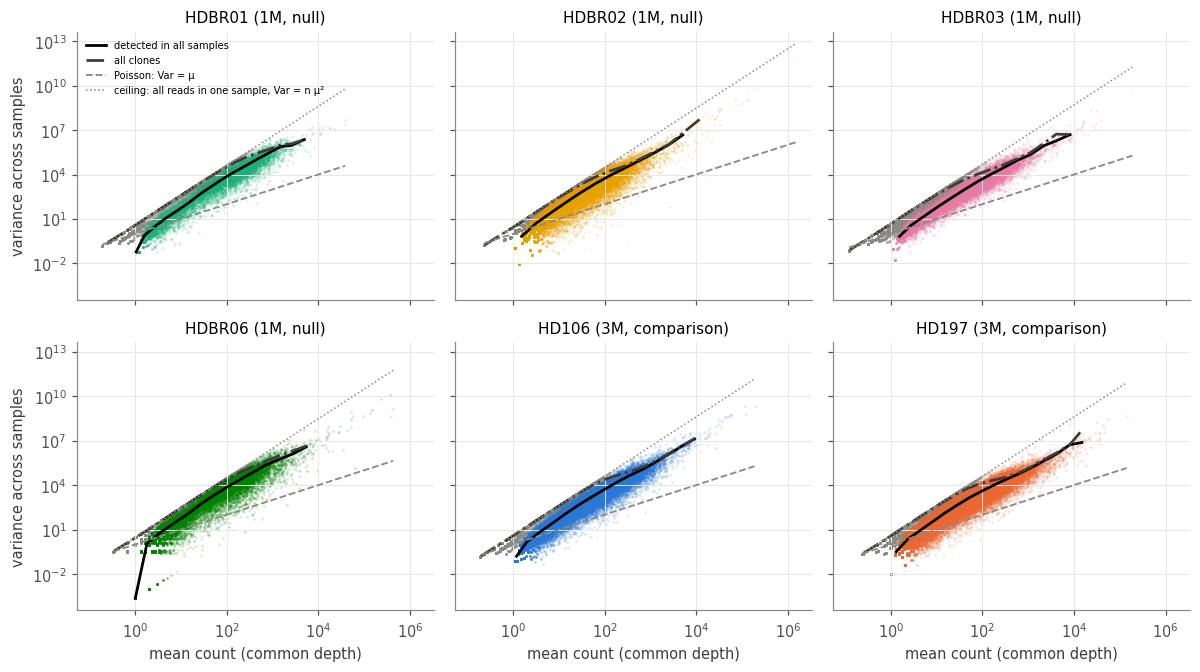

In [4]:
def mean_variance(g, mode='all', c=1):
    days = np.sort(g['day'].unique())
    L = g.groupby('day', observed=True)['lib'].first().reindex(days).to_numpy()
    X = (g.pivot_table(index='clono', columns='day', values='count', aggfunc='sum',
                       fill_value=0, observed=True)
           .reindex(columns=days, fill_value=0).to_numpy(float))
    keep = (X >= c).all(axis=1) if mode == 'all' else np.ones(len(X), dtype=bool)
    Y = X[keep] * (L.mean() / L)                 # counts at a common depth
    return Y.mean(axis=1), Y.var(axis=1, ddof=1), len(days)

def binned(m, v, edges, min_n=20):
    k = np.digitize(m, edges)
    grp = [i for i in np.unique(k) if (k == i).sum() >= min_n]
    return (np.array([m[k == i].mean() for i in grp]),
            np.array([v[k == i].mean() for i in grp]))

rng = np.random.default_rng(0)
fig, axes = plt.subplots(2, 3, figsize=(11, 6.2), sharex=True, sharey=True)
for ax, p in zip(axes.ravel(), NULL_DONORS + COMPARE_DONORS):
    g = chk.subset(d_qc, p)
    m_all, v_all, n_s = mean_variance(g, 'all')
    m_any, v_any, _ = mean_variance(g, 'any')
    idx = rng.choice(len(m_any), size=min(len(m_any), 100_000), replace=False)
    ax.scatter(m_any[idx], v_any[idx], s=1, color=GREY, alpha=0.05, rasterized=True)
    ax.scatter(m_all, v_all, s=1, color=COLOR[p], alpha=0.10, rasterized=True)
    edges = np.logspace(np.log10(m_any.min()), np.log10(m_any.max()), 22)
    for (m, v), col, lab, ls in [((m_all, v_all), 'black', 'detected in all samples', '-'),
                                 ((m_any, v_any), INK, 'all clones', '-.')]:
        mb, vb = binned(m, v, edges)
        ax.plot(mb, vb, color=col, lw=1.8, ls=ls, label=lab)
    mm = np.logspace(np.log10(m_any.min()), np.log10(m_any.max()), 50)
    ax.plot(mm, mm, color=GREY, ls='--', lw=1.2, label='Poisson: Var = μ')
    ax.plot(mm, n_s * mm ** 2, color=GREY, ls=':', lw=1.0,
            label='ceiling: all reads in one sample, Var = n μ²')
    ax.set(xscale='log', yscale='log',
           title=f"{short(p)} ({'1M, null' if p in NULL_DONORS else '3M, comparison'})")
for ax in axes[-1]:
    ax.set_xlabel('mean count (common depth)')
for ax in axes[:, 0]:
    ax.set_ylabel('variance across samples')
axes[0, 0].legend(fontsize=6.5, loc='upper left')
fig.tight_layout()

**What this shows.** Among clones detected in every sample (coloured points, black
line), the variance exceeds the Poisson value ($\mathrm{Var} = \mu$) by one to three
orders of magnitude and grows roughly as $\mu^2$ at high means, as the NB's
$\mu^2/\phi$ term predicts. A Poisson model would read this ordinary sample-to-sample
noise as real change and call most clones non-neutral.

Two features of the figure are not about overdispersion:
* **The upper edge (dotted line)** is a mathematical ceiling: a clone with mean $\mu$
  over $n$ samples has variance at most $n\mu^2$, reached when all its reads fall in one
  sample. Clones seen in a single sample sit on it, which shapes the "all clones" curve.
* **The dip of the black line below Poisson at low means** is a selection effect: a clone
  of mean ~1 that happens to be seen in every sample must have read 1, 1, 1, ..., so its
  variance is near zero. Conditioning on detection makes noise look smaller than it is,
  which is why $\phi$ is estimated with a truncated likelihood (Section 2.4).

## 2.4 Estimating $\phi$

$\phi$ is estimated per donor from the donor's own clones, with three ingredients.

* **1. Detected counts only, with a truncated likelihood.** A clone missing from a sample
has zero reads, but that is weak evidence that it is absent: it may simply not have been
captured (Section 2.7). Only detected counts
are used, and since a count is only reported when it reaches the sample's cutoff
$c_t$ (Section 1.2), each is modelled *conditional on detection*:

    $$P(x_{ct} \mid x_{ct} \ge c_t) = \frac{\mathrm{NB}(x_{ct};\ \mu_{ct}, \phi)}{P_{NB}(X \ge c_t;\ \mu_{ct}, \phi)}.$$

    Without the denominator, the counts that fell below the cutoff are silently missing
    from the low tail and the noise looks smaller than it is. 
    As a side note, in the literature, it is common to see the term *zero truncated likelihood* which corresponds to the specific case of $c_{t}=1$. This is the case when full raw count data is available without any cutoff. 

* **2. Profiling out the clone frequencies.** Every clone has its own unknown
$\lambda_c$ (thousands of nuisance parameters). For each trial value of $\phi$, every
$\lambda_c$ is set to its maximum-likelihood value (Fisher scoring), which gives the
profile likelihood $\ell_p(\phi) = \max_\lambda \ell(\phi, \lambda)$. This is, for each tested $\phi$ the values of $\lambda_c$ are computed in a inner optimization loop, where the starting value is the pooled frequency 
$$\hat{\lambda_{c}} = \frac{\sum_{t} x_{c,t}}{\sum_{t}D_{t}f_{t}}$$
    The nested optimization procedure, altough more precise is also more expensive, so a chaper version using directly the pooled $\hat{\lambda_c}$ is avaliable.

* **3. Cox–Reid adjustment.** Each clone has only 2–5 observations but its own fitted
$\hat\lambda_c$, which absorbs part of the noise and introduces bias. The adjusted profile likelihood (also known as Cox-Reid adjustment **REFERENCE**)

$$\ell_{CR}(\phi) = \ell_p(\phi) - \tfrac12 \sum_c \log I_c(\hat\lambda_c, \phi)$$

    ($I_c$: the Fisher information for $\log\lambda_c$) removes that bias.

* **4. Clones used.** Detected in at least 2 samples (a clone seen once carries no
information about variation between samples), and with pooled frequency at least
$10^{-5}$ of the sample depth (the frequency floor, Section 2.5).

The table compares, on the real donors, the chosen estimator with two simplified ones.

In [5]:
est = chk.estimator_table(nb, d_qc, NULL_DONORS + COMPARE_DONORS)
print('With the frequency floor (pooled frequency >= 1e-5): the values used')
display(est.loc['with floor'].round(3))
print('Without a floor (all clones detected >= 2 times): for comparison, see Section 2.5')
display(est.loc['no floor'].round(3))

With the frequency floor (pooled frequency >= 1e-5): the values used


,truncated + Cox-Reid (used),not truncated,no Cox-Reid,n_clones
donor,,,,
HD106,2.087,2.088,2.844,7142
HD197,3.316,3.316,4.478,7294
HDBR01,1.085,1.118,1.589,11391
HDBR02,1.606,1.631,2.470,7668
HDBR03,1.509,1.539,2.041,16345
HDBR06,1.158,1.189,1.800,9449


Without a floor (all clones detected >= 2 times): for comparison, see Section 2.5


,truncated + Cox-Reid (used),not truncated,no Cox-Reid,n_clones
donor,,,,
HD106,0.451,1.816,2.237,167239
HD197,2.740,2.083,2.582,229111
HDBR01,0.139,1.367,1.605,90868
HDBR02,2.612,1.865,2.523,68048
HDBR03,0.021,1.868,2.161,159850
HDBR06,0.133,1.615,1.960,58818


Without a floor the three estimators disagree substantially, and none of them can be
trusted there: Section 2.5 shows by simulation that near the detection limit every
estimator is biased. With the floor, the chosen estimator (truncated + Cox–Reid) recovers
a known $\phi$; leaving out Cox–Reid inflates $\phi$ by ~1.4×. As expected from the input
difference, the 3M donors (HD) have a clearly higher $\phi$ (less noise) than the 1M donors.

## 2.5 Why $\phi$ is estimated on abundant clones only (frequency floor)

The raw tables contain every clonotype with at least one read ($c = 1$), so most clones
sit right at the detection limit: one or two reads, seen at only some timepoints. We
estimate the donor dispersion $\phi$ only from clones whose pooled frequency is at least
$10^{-5}$ of the sample depth, which at these depths ($D_t \approx 5$–$21 \times 10^6$)
means a pooled mean of roughly 50–210 reads. Here is why.

**Estimators fail near the detection limit.** A clone is recorded at a timepoint only if
its count is at least $c$, so the counts we see near the limit are a truncated sample of
the underlying NB distribution. The simulation below fits the three estimators to
neutral donors with a known $\phi$ (5 timepoints, Pareto-distributed clone frequencies,
so that most clones sit near the limit, as in TCR data):

* *legacy* (pooled mean plugged in) and *CR* (Cox-Reid profile) ignore the truncation.
  Without a floor they **overestimate $\phi$ 2–4×**, because the zeros that would show
  the overdispersion are never observed.
* *CR+trunc* models the truncation, but with only ~5 timepoints per clone it is
  **unstable** without a floor: depending on $\phi$ it lands anywhere from ~0.1× to ~1.4×
  the true value, and the result is not reproducible across numerical settings. Clones
  whose every count equals the cutoff carry no information and break the inner fit.

**A frequency floor fixes the truncated estimator.** Once clones need a pooled mean of at
least about 10 reads, CR+trunc recovers the true $\phi$ to within a few percent for $\phi$
from 0.5 to 4. The untruncated estimators are still biased upward when $\phi$ is small.
Truncation barely affects abundant clones, so their information about $\phi$ is
reliable. The production floor (50–210 reads) is above this, so it is conservative.
Recovery on the real donor designs was also checked (truncated + Cox–Reid within 0–7%
for $\phi$ = 0.2–1.2 on the HD106, HDBR03 and HDBR06 designs).

**Consequences for the patient test**
1. Patient clones are tested only within the frequency range where $\phi$ was estimated
   (the same floor, computed the same way).
2. In the test, missing timepoints and counts below $k = 3$ are not used as evidence
   of change (Section 2.7).

**Limitation and next phase.** The floor throws away information: near-cutoff clones
should tell us how $\phi$ behaves at low frequency, which matters if $\phi$ depends on
frequency. Recovering it needs a model that handles truncation without per-clone
nuisance parameters, for example by integrating each clone's frequency over a fitted
clone-size distribution. That is planned for phase 2.

In [6]:
recovery = chk.phi_recovery_simulation(nb)
recovery.round(2)     # median phi_hat / phi_true over 3 replicates; 1.00 = unbiased

fitter                legacy    CR  CR+trunc  clones kept
phi_true floor_reads                                     
0.5      0              3.77  3.84      0.14         2370
         5              1.96  2.04      0.96          283
         10             1.63  1.70      1.01          126
         20             1.41  1.47      0.95           59
1.0      0              2.70  2.71      0.21         2680
         5              1.36  1.41      0.99          256
         10             1.17  1.21      0.97          116
         20             1.09  1.15      1.02           62
4.0      0              1.89  1.90      1.40         2986
         5              1.08  1.11      1.01          216
         10             1.03  1.09      1.07          106
         20             1.07  1.14      1.14           57

## 2.6 $\phi$ depends on clone frequency

With fewer molecules behind a rare clone, its counts fluctuate more, relative to their
mean, than those of an abundant clone. The noise then has two parts,

$$\frac{1}{\phi(f)} \approx \frac{A}{f} + B,$$

sampling of cells/molecules ($A/f$, larger with lower input) and a frequency-independent
part ($B$: amplification, transcripts per cell, biology). A single $\phi$ cannot describe
both, so $\phi$ is estimated per donor in frequency bins (95% profile-likelihood
intervals), and a line $\log\phi = a + b\log_{10} f$ is fitted through the bins.
`slope_z` = slope / standard error; `line_chi2` ≫ `line_df` means the trend is curved.

The estimator itself does not create trends: on simulated donors with constant $\phi$ the
fitted slope was 0 within its error, and known trends were recovered.

**Reference for patients**: at each frequency, the smallest $\phi$ of the four null
donors (the noisiest donor there). Using the noisiest donor makes the test conservative:
a patient clone is called non-neutral only if it changes more than the noisiest healthy
donor's clones would.

,donor,null,phi_global,n_clones,slope_b,slope_se,slope_z,line_chi2,line_df
0,HDBR01,True,1.085,11391,0.826,0.043,19.349,7.147,4
1,HDBR02,True,1.606,7668,1.075,0.042,25.369,18.594,4
2,HDBR03,True,1.509,16345,0.889,0.027,32.705,52.697,4
3,HDBR06,True,1.158,9449,0.839,0.040,21.028,29.610,4
4,HD106,False,2.087,7142,1.348,0.039,34.412,10.392,4
5,HD197,False,3.316,7294,1.705,0.033,51.463,13.009,4


Reference trend (pointwise minimum over the null donors): PhiTrend(log10 f in [-5.00, -4.14], phi in [0.853, 1.45])


,log10_freq,phi
0,-5.000,0.853
1,-4.829,0.981
2,-4.657,1.128
3,-4.486,1.297
4,-4.314,1.451
5,-4.143,1.451


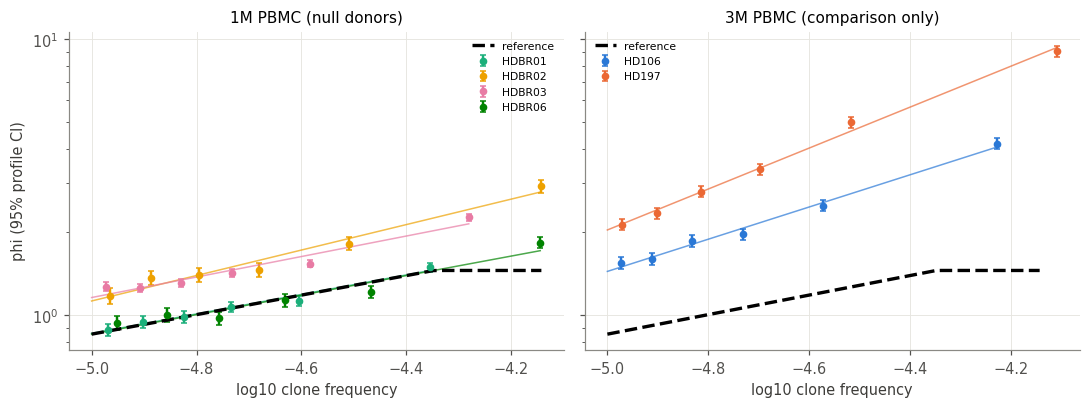

In [7]:
noise_summary, noise_bins, noise_fits = chk.noise_by_donor(
    nb, d_qc, NULL_DONORS + COMPARE_DONORS, NULL_DONORS)
null_fits = {p: noise_fits[p] for p in NULL_DONORS}
phi_ref_trend = chk.reference_trend(nb, null_fits)

display(noise_summary.assign(donor=noise_summary['donor'].map(short)).round(3))
print('Reference trend (pointwise minimum over the null donors):', phi_ref_trend)
display(phi_ref_trend.table(np.linspace(phi_ref_trend.log10_f[0],
                                        phi_ref_trend.log10_f[-1], 6)).round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, grp, title in [(axes[0], NULL_DONORS, '1M PBMC (null donors)'),
                       (axes[1], COMPARE_DONORS, '3M PBMC (comparison only)')]:
    for p in grp:
        b = noise_bins[noise_bins['donor'] == p]
        ax.errorbar(b['log10_freq'], b['phi'], yerr=[b['phi'] - b['ci_lo'], b['ci_hi'] - b['phi']],
                    fmt='o', ms=4, capsize=2, color=COLOR[p], label=short(p))
        tt = noise_fits[p]['trend'].table()
        ax.plot(tt['log10_freq'], tt['phi'], color=COLOR[p], lw=1, alpha=0.7)
    rt = phi_ref_trend.table()
    ax.plot(rt['log10_freq'], rt['phi'], color='k', lw=2.2, ls='--', label='reference')
    ax.set(yscale='log', title=title, xlabel='log10 clone frequency')
    ax.legend(fontsize=7)
axes[0].set_ylabel('phi (95% profile CI)')
fig.tight_layout()

**What this shows.** $\phi$ rises clearly with frequency in every donor (|z| ≫ 2), i.e.
rare clones are noisier, as cell/molecule sampling predicts. A single $\phi$ would be
anti-conservative for clones near the floor and needlessly conservative for abundant
ones, so the trend reference is used for patients. The 3M donors sit well above the 1M
donors at every frequency. The reference is held constant above the highest bin centre,
which is conservative for the most abundant clones.

## 2.7 Missing timepoints and very low counts

With raw data, a missing timepoint means **zero reads**. That does not mean the clone left
the blood: at 1M PBMC a clone at frequency $10^{-5}$ rests on a handful of cells or
molecules, and missing it entirely is common. The check below measures this directly.
For each donor, each sample is held out in turn; clones detected in at least 2 of the
other samples and above the floor there are checked for whether they are missing in the
held-out sample. The observed miss rate is compared with the same procedure applied to
donors simulated from the fitted model (NB plus cell-sampling dropout, the donor's own
$\phi$ and per-sample input $N_t$). Comparing with simulated donors (not a formula) is
needed because each clone's frequency is estimated from only a few samples.

,donor,bin,n,obs_miss,sim_miss,excess,pred_dropout,pred_nb
0,HDBR01,"[1e-05, 2e-05)",20594,0.4650,0.1444,0.3206,0.1370,0.0036
1,HDBR01,"[2e-05, 5e-05)",11044,0.3181,0.0723,0.2458,0.0224,0.0017
2,HDBR01,"[5e-05, 0.0001)",2100,0.1624,0.0143,0.1481,0.0009,0.0007
3,HDBR01,"[0.0001, 0.001)",692,0.0592,0.0016,0.0576,0.0003,0.0003
4,HDBR01,"[0.001, 1.0)",21,0.0000,0.0000,0.0000,0.0000,0.0000
0,HDBR02,"[1e-05, 2e-05)",8816,0.2138,0.1017,0.1121,0.0709,0.0017
1,HDBR02,"[2e-05, 5e-05)",5869,0.1033,0.0367,0.0665,0.0061,0.0005
2,HDBR02,"[5e-05, 0.0001)",1669,0.0312,0.0036,0.0276,0.0001,0.0001
3,HDBR02,"[0.0001, 0.001)",1151,0.0087,0.0000,0.0087,0.0000,0.0000
4,HDBR02,"[0.001, 1.0)",126,0.0238,0.0000,0.0238,0.0000,0.0000


,donor,day,n,obs_miss,sim_miss,excess,pred_dropout,pred_nb
0,HDBR01,0,8700,0.4160,0.1366,0.2793,0.1123,0.0036
1,HDBR01,21,8398,0.3302,0.0630,0.2672,0.0471,0.0029
2,HDBR01,42,8897,0.4236,0.1293,0.2943,0.1156,0.0021
3,HDBR01,126,8456,0.3916,0.1004,0.2911,0.0791,0.0025
0,HDBR02,0,5937,0.1379,0.0739,0.0641,0.0385,0.0013
1,HDBR02,48,5622,0.2005,0.0640,0.1364,0.0303,0.0004
2,HDBR02,71,6072,0.1005,0.0736,0.0269,0.0432,0.0012
0,HDBR03,0,13644,0.4121,0.1495,0.2626,0.1350,0.0007
1,HDBR03,21,14345,0.1971,0.0786,0.1185,0.0637,0.0023
2,HDBR03,35,14204,0.3530,0.0832,0.2698,0.0659,0.0014


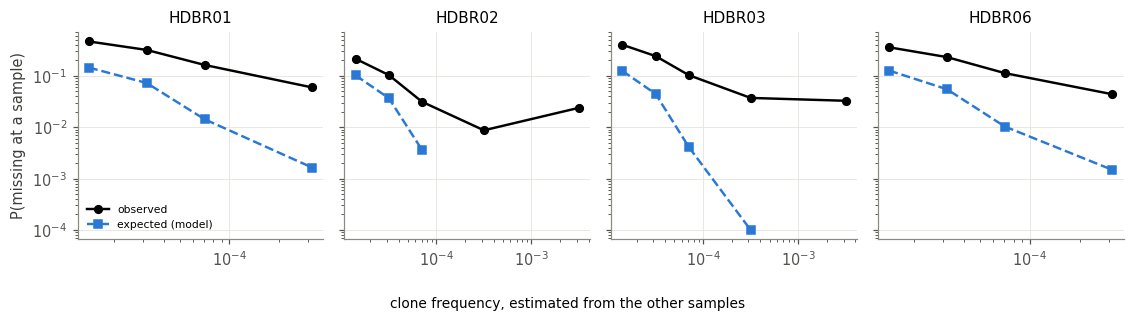

In [8]:
phis_null = dict(zip(noise_summary['donor'], noise_summary['phi_global']))
absence_by_bin, absence_by_sample = chk.absence_diagnostic(
    nb, d_qc, {p: phis_null[p] for p in NULL_DONORS})
display(absence_by_bin.round(4))
display(absence_by_sample.round(4))
chk.plot_absence(absence_by_bin);

**What this shows.** Abundant clones are missing far more often than the model allows,
in every donor, every sample and every frequency bin (by a factor of 3 to over 100). The
same capture process also produces **near-dropouts**: a clone captured from one or two
molecules gives a handful of reads instead of hundreds.

**Decision for the test.**
* Use the **truncated likelihood**: only detected timepoints contribute,
  $P(x \mid x \ge k)$, so a missing timepoint is not read as a change. With the model's
  dropout term instead, every absence counted as strong evidence of change, and the
  leave-one-donor-out test produced up to 139 false discoveries per donor (Section 2.8).
* **Counts below $k = 3$ are not trusted** as exact values (treated like a miss). This
  costs ~1% of tested clones and lowers the error rate in every donor.

The cost is power: a clone that contracts all the way to zero is seen only through its
detected timepoints. Recovering that information requires a better capture model
(phase 2).

## 2.8 Validation: leave-one-donor-out

Each null donor is held out in turn and tested **exactly like a patient**: size-factor
offsets, $\phi$ reference = pointwise minimum of the other three donors' trends,
truncated test with $k = 3$, abundance filter $10^{-5}$. Healthy donors are neutral, so
every call is a false positive.

**Pass criteria (fixed before running):** for every held-out donor,
* FPR at $p < 0.05$ at most 5%, allowing for binomial noise
  ($\le 0.05 + 2\sqrt{0.05 \cdot 0.95 / n}$);
* at most one call at FDR 5% (Benjamini–Hochberg).

The table by number of missing timepoints is a **diagnostic, not a criterion**: the number
of misses is part of the outcome, so even under a correct model p-values are skewed small
for clones with a miss and large for fully detected ones (in simulation, 30–37% vs 1–4%
at $p < 0.05$ with ~4% overall).

In [9]:
cache = RESULTS / 'lodo_final.pkl'
if cache.exists():
    lodo_final = pd.read_pickle(cache)
else:
    lodo_final = chk.lodo(nb, d_qc, null_fits, likelihood='truncated', reference='min', k=3)
    lodo_final.to_pickle(cache)
per_donor, verdict = chk.lodo_summary(lodo_final)
display(verdict.round(3))
display(per_donor.round(3))
print('Where the false calls sit, by clone frequency (own_vs_ref < 1: donor noisier than its reference):')
display(chk.fpr_by_frequency(nb, d_qc, lodo_final, null_fits).round(3))
print('By number of missing timepoints (diagnostic only):')
display(chk.lodo_by_miss(lodo_final).round(3))

,likelihood,reference,k,all_pass,max_FPR,total_BH,pooled_FPR,failing
0,truncated,min,3,False,0.066,0.0,0.043,HDBR06


,likelihood,reference,k,held_out,n_tested,FPR_05,limit,FPR_01,BH,frac_expanding_sig,frac_expanding_all,passes
0,truncated,min,3,HDBR01,4995.0,0.049,0.056,0.010,0.0,0.295,0.485,True
1,truncated,min,3,HDBR02,5018.0,0.008,0.056,0.001,0.0,0.763,0.563,True
2,truncated,min,3,HDBR03,8739.0,0.048,0.055,0.010,0.0,0.183,0.430,True
3,truncated,min,3,HDBR06,4606.0,0.066,0.056,0.017,0.0,0.709,0.519,False


Where the false calls sit, by clone frequency (own_vs_ref < 1: donor noisier than its reference):


,donor,bin,n,FPR_05,frac_expanding_sig,own_vs_ref
0,HDBR01,"[1e-05, 2e-05)",2309,0.048,0.309,1.006
1,HDBR01,"[2e-05, 5e-05)",2080,0.055,0.287,1.006
2,HDBR01,"[5e-05, 0.0001)",446,0.040,0.278,0.852
3,HDBR01,"[0.0001, 0.001)",155,0.006,0.000,0.848
4,HDBR01,"[0.001, 1.0)",5,0.000,NaN,0.848
5,HDBR02,"[1e-05, 2e-05)",2326,0.011,0.760,1.369
6,HDBR02,"[2e-05, 5e-05)",1751,0.007,0.750,1.493
7,HDBR02,"[5e-05, 0.0001)",525,0.002,1.000,1.911
8,HDBR02,"[0.0001, 0.001)",377,0.000,NaN,1.927
9,HDBR02,"[0.001, 1.0)",39,0.000,NaN,1.927


By number of missing timepoints (diagnostic only):


,likelihood,reference,k,held_out,n_miss,n,FPR_05
0,truncated,min,3,HDBR01,0,3187,0.041
1,truncated,min,3,HDBR01,1,1808,0.062
2,truncated,min,3,HDBR02,0,5018,0.008
3,truncated,min,3,HDBR03,0,5786,0.030
4,truncated,min,3,HDBR03,1,1946,0.072
5,truncated,min,3,HDBR03,2,1007,0.106
6,truncated,min,3,HDBR06,0,4606,0.066


### 2.8.1 Alternatives that were considered

The same leave-one-donor-out run for the alternatives behind each choice: the dropout
likelihood instead of the truncated one, the mean of the other donors' $\phi$ (on the
$1/\phi$ scale) instead of the minimum, and $k = 1, 3, 5$. This takes ~10× longer than the
final run; set `RUN_VARIANTS = True` to recompute (results are cached).

In [10]:
RUN_VARIANTS = False
cache = RESULTS / 'lodo_variants.pkl'
variants = [('dropout', 'min', 1), ('dropout', 'mean', 1), ('truncated', 'mean', 1),
            ('truncated', 'min', 1), ('truncated', 'min', 3), ('truncated', 'min', 5)]
if cache.exists() and not RUN_VARIANTS:
    lodo_var = pd.read_pickle(cache)
elif RUN_VARIANTS:
    lodo_var = pd.concat([chk.lodo(nb, d_qc, null_fits, likelihood=l, reference=r, k=k)
                          for l, r, k in variants], ignore_index=True)
    lodo_var.to_pickle(cache)
else:
    lodo_var = None
    print('Variants not computed: set RUN_VARIANTS = True.')
if lodo_var is not None:
    per_var, verdict_var = chk.lodo_summary(lodo_var)
    display(verdict_var.round(3))
    display(per_var.pivot_table(index=['likelihood', 'reference', 'k'], columns='held_out',
                                values=['FPR_05', 'BH']).round(3))

Variants not computed: set RUN_VARIANTS = True.


## 2.9 Where this leaves the pipeline

**Validated** (leave-one-donor-out on the four null donors, run of 2026-11-03 — check the
tables above after any rerun): HDBR01, HDBR02 and HDBR03 pass; **HDBR06 is at 6.6%**
($p < 0.05$, limit 5.6%); **no false discoveries at FDR 5% in any donor**; pooled FPR
over the four donors 4.3%. The alternatives fail more often: the dropout likelihood
(false discoveries in HDBR01 and HDBR03, up to 139), the mean reference (more false calls
in every donor), TMM offsets (HDBR03 at 8.1%).

**Limitations**
* **HDBR06.** Its excess sits among low-frequency clones, where its noise matches the
  reference; its false calls lean towards expansions after day 0 while its clones overall
  are balanced. Either part of the day-0 sample was under-captured (its miss rate is the
  highest of its three samples), or some clones really expanded. These cannot be separated
  with the present data.
* **Four null donors.** The reference is effectively the noisiest of three donors in each
  leave-one-out fold. A patient noisier than every donor would be over-called.
* **Power.** Missing timepoints and very low counts are not used, so contractions to zero
  are seen only through detected timepoints. Power for expansions, contractions and
  transient clones under this configuration still has to be measured by simulation.
* **Clones below the floor** (pooled frequency $< 10^{-5}$) are not tested.

**Next (phase 2): a capture model.** Missed clones, near-dropouts, the frequency trend of
$\phi$ and the input effect all come from one process: sampling of cells/molecules
followed by amplification. A two-stage model (molecules $M_{ct} \sim \mathrm{NB}(N_t f_c, k)$,
reads $\mid M_{ct}$ amplified) would describe all four, let missing timepoints and low
counts be used again, and give a testable prediction: $N_t$ about 3× larger for the 3M donors.

In [11]:
# =============================================================================
# HDBR06 sensitivity analysis
#
#   1. Independent sample-quality indicators for every sample (not derived from the
#      trajectory test): is HDBR06 day 0 technically unusual?
#   2. Trajectory test of HDBR06 with and without day 0. Without day 0 only two samples
#      remain, so the two-sample test is calibrated on the other null donors (their last
#      two samples) before comparing.
#   3. Are HDBR06's false calls predominantly expansions after day 0? Compared with the
#      other donors' first sample, so that the expected share is known.
#   4. Alternative size-factor estimates for HDBR06.
#
# Reference throughout: pointwise minimum of the OTHER three null donors' phi trends
# (as in Section 2.8); truncated test, counts below k = 3 not trusted.
# Needs (Notebook 2 v2): healthy_raw, d_qc, null_fits, NULL_DONORS, nb, chk.
# =============================================================================
import numpy as np
import pandas as pd
 
H6 = [p for p in NULL_DONORS if 'HDBR06' in p][0]
OTHERS = [p for p in NULL_DONORS if p != H6]
K = 3
 
 
def wide(g, col='count'):
    days = [int(d) for d in sorted(g['day'].unique())]
    X = (g.pivot_table(index='clono', columns='day', values=col, aggfunc='sum',
                       fill_value=0, observed=True).reindex(columns=days, fill_value=0))
    return days, X
 
 
def run_test(g, ref, min_detect=3):
    g = g.assign(c_t=K)
    r = nb.nb_trajectory_test(g, ref, likelihood='truncated', cutoff_col='c_t',
                              min_detect=min_detect, min_freq=chk.FLOOR)
    return nb.add_qvalues(r, p_col='p_value', by='patient')
 
 
def summarise(r, label, **extra):
    s = r['p_value'] < 0.05
    n = len(r)
    return dict(analysis=label, **extra, n_tested=n, FPR_05=s.mean(),
                limit=0.05 + 2 * np.sqrt(0.0475 / max(n, 1)),
                BH=int((r['q_value'] < 0.05).sum()),
                frac_expanding_sig=(r.loc[s, 'beta'] > 0).mean(),
                frac_expanding_all=(r['beta'] > 0).mean())
 
 
# ---- 1. sample-quality indicators ---------------------------------------------------
def expected_richness(x, depth):
    """Expected number of clonotypes if the sample had `depth` reads (rarefaction)."""
    N = x.sum()
    return float(np.sum(1 - np.exp(depth * np.log1p(-np.minimum(x / N, 1 - 1e-12))))) \
        if depth < N else float((x > 0).sum())
 
 
qc_rows = []
common_depth = float(healthy_raw[healthy_raw['patient'].isin(NULL_DONORS)]
                     .groupby(['patient', 'day'], observed=True)['D_t'].first().min())
for p in NULL_DONORS:
    raw = chk.subset(healthy_raw, p)
    days, X = wide(raw)
    Xv = X.to_numpy(float)
    D = raw.groupby('day', observed=True)['D_t'].first().reindex(days).to_numpy(float)
    kept = set(int(d) for d in chk.subset(d_qc, p)['day'].unique())
    umi = 'umi' in raw.columns or 'UMI' in raw.columns
    if umi:
        ucol = 'umi' if 'umi' in raw.columns else 'UMI'
        _, U = wide(raw, ucol)
        Uv = U.to_numpy(float)
    for j, t in enumerate(days):
        o = [i for i in range(len(days)) if i != j]
        det_o = (Xv[:, o] >= 1)
        f_o = np.where(det_o.sum(1) >= 2, (Xv[:, o] * det_o).sum(1)
                       / np.maximum((det_o * D[o]).sum(1), 1), 0)
        ab = f_o >= chk.FLOOR
        col = Xv[:, j]
        det = ab & (col >= 1)
        row = dict(donor=short(p), day=t, qc_kept=t in kept, D_t=D[j],
                   richness_at_common_depth=expected_richness(col[col > 0], common_depth),
                   reads_per_clonotype=col.sum() / max((col >= 1).sum(), 1),
                   top10_share=np.sort(col)[-10:].sum() / col.sum(),
                   abundant_missing=float((col[ab] < 1).mean()),
                   abundant_below_3=float((col[ab] < K).mean()),
                   abundant_level=float(np.median(np.log2(col[det] / D[j] / f_o[det]))))
        if umi:
            uc = Uv[:, j]
            m = (col >= 1) & (uc >= 1)
            row['reads_per_umi'] = float(np.median(col[m] / uc[m]))
        qc_rows.append(row)
sample_qc_table = pd.DataFrame(qc_rows)
# relative to the same donor's other samples (log2 ratio to the donor median)
for c in ['richness_at_common_depth', 'reads_per_clonotype', 'top10_share',
          'abundant_missing', 'abundant_level'] + (['reads_per_umi'] if umi else []):
    v = sample_qc_table[c] if c != 'abundant_level' else 2 ** sample_qc_table[c]
    sample_qc_table[c + '_vs_donor'] = np.log2(
        v / v.groupby(sample_qc_table['donor']).transform('median'))
print('1. Sample-quality indicators (computed from the sample alone or from the other '
      'samples of the same donor; none uses the trajectory test).')
print('   *_vs_donor: log2 ratio to the donor median. Compare HDBR06 day 0 with the spread '
      'of all other samples; abundant_level is negative for every sample by selection.')
display(sample_qc_table.round(3))
 
# ---- 2. with and without day 0, and the two-sample calibration ---------------------
ref6 = chk.reference_trend(nb, null_fits, exclude=H6)
g6 = chk.subset(d_qc, H6)
days6 = [int(d) for d in sorted(g6['day'].unique())]
rows = []
r_full = run_test(g6, ref6)
rows.append(summarise(r_full, f'{short(H6)} all samples', days=days6))
g6_nod0 = nb.attach_size_factor_offset(g6[g6['day'] != days6[0]])
r_nod0 = run_test(g6_nod0, ref6, min_detect=2)
rows.append(summarise(r_nod0, f'{short(H6)} without day {days6[0]}', days=days6[1:]))
for p in OTHERS:                    # control: the same two-sample test on the other donors
    g = chk.subset(d_qc, p)
    dd = [int(d) for d in sorted(g['day'].unique())]
    g2 = nb.attach_size_factor_offset(g[g['day'].isin(dd[-2:])])
    ref_p = chk.reference_trend(nb, null_fits, exclude=p)
    rows.append(summarise(run_test(g2, ref_p, min_detect=2),
                          f'control {short(p)}: last two samples', days=dd[-2:]))
with_without = pd.DataFrame(rows)
with_without['passes'] = (with_without['FPR_05'] <= with_without['limit']) & \
                         (with_without['BH'] <= 1)
print('\n2. HDBR06 with and without day 0; two-sample controls on the other donors')
display(with_without.round(3))
 
# ---- 3. which sample drives the false calls ----------------------------------------
def extreme_sample_table(g, r, label):
    days, X = wide(g)
    L = g.groupby('day', observed=True)['lib'].first().reindex(days).to_numpy(float)
    rr = r.assign(clono=r['clono'].astype(str))
    Xs = X.copy(); Xs.index = Xs.index.astype(str)
    F = Xs.loc[rr['clono']].to_numpy(float) / L[None, :]
    with np.errstate(divide='ignore'):
        lF = np.log(np.where(F > 0, F, np.nan))
    dev = lF - np.nanmean(lF, axis=1, keepdims=True)
    j = np.nanargmax(np.abs(dev), axis=1)
    rr['extreme_day'] = np.array(days)[j]
    rr['first_sample_low'] = (j == 0) & (dev[np.arange(len(j)), 0] < 0)
    sig = rr['p_value'] < 0.05
    out = (rr.groupby(sig.map({True: 'false calls', False: 'other clones'}))
             .agg(n=('clono', 'size'),
                  frac_first_sample_low=('first_sample_low', 'mean'),
                  frac_expanding=('beta', lambda b: (b > 0).mean())))
    out['donor'] = label
    return out.reset_index().rename(columns={'p_value': 'group'})
 
 
pattern = [extreme_sample_table(g6, r_full, short(H6))]
for p in OTHERS:
    g = chk.subset(d_qc, p)
    pattern.append(extreme_sample_table(g, run_test(g, chk.reference_trend(nb, null_fits,
                                                                           exclude=p)),
                                        short(p)))
print('\n3. Share of clones whose most extreme sample is the FIRST one and is LOW '
      '(i.e. an expansion after the first sample). Compare HDBR06 with the other donors.')
display(pd.concat(pattern, ignore_index=True)
          [['donor', 'group', 'n', 'frac_first_sample_low', 'frac_expanding']].round(3))
 
# ---- 4. alternative size factors for HDBR06 -----------------------------------------
def alt_size_factors(g, method='median', min_freq=1e-5, trim=0.2):
    days, X = wide(g)
    D = g.groupby('day', observed=True)['D_t'].first().reindex(days).to_numpy(float)
    Xv = X.to_numpy(float)
    F = Xv / D[None, :]
    ref = (Xv >= 1).all(1) & (F.mean(1) >= min_freq)
    R = np.log(F[ref]) - np.log(F[ref]).mean(1, keepdims=True)
    if method == 'median':
        s = np.median(R, axis=0)
    elif method == 'trimmed':
        from scipy.stats import trim_mean
        s = trim_mean(R, trim, axis=0)
    s = np.exp(s - s.mean())
    return dict(zip(days, s)), int(ref.sum())
 
 
variants = {'median of ratios, f >= 1e-5 (used)': ('median', 1e-5),
            'median of ratios, f >= 1e-4': ('median', 1e-4),
            'median of ratios, f >= 3e-6': ('median', 3e-6),
            'trimmed mean (20%) of ratios, f >= 1e-5': ('trimmed', 1e-5)}
rows = []
for name, (m, mf) in variants.items():
    sfd, nref = alt_size_factors(g6, m, mf)
    g = g6.assign(lib=g6['D_t'] * g6['day'].map(sfd).astype(float))
    rows.append(summarise(run_test(g, ref6), name, n_ref_clones=nref,
                          size_factors={d: round(v, 3) for d, v in sfd.items()}))
g = g6.assign(lib=g6['D_t'].astype(float))
rows.append(summarise(run_test(g, ref6), 'no correction (D_t only)'))
if 'tmm_factor' in g6:
    g = g6.assign(lib=g6['D_t'] * g6['tmm_factor'])
    rows.append(summarise(run_test(g, ref6), 'TMM'))
alt_sf = pd.DataFrame(rows)
alt_sf['passes'] = (alt_sf['FPR_05'] <= alt_sf['limit']) & (alt_sf['BH'] <= 1)
print(f'\n4. {short(H6)} with alternative size factors (all samples)')
display(alt_sf.round(3))
 


1. Sample-quality indicators (computed from the sample alone or from the other samples of the same donor; none uses the trajectory test).
   *_vs_donor: log2 ratio to the donor median. Compare HDBR06 day 0 with the spread of all other samples; abundant_level is negative for every sample by selection.


,donor,day,qc_kept,D_t,richness_at_common_depth,reads_per_clonotype,top10_share,abundant_missing,abundant_below_3,abundant_level,richness_at_common_depth_vs_donor,reads_per_clonotype_vs_donor,top10_share_vs_donor,abundant_missing_vs_donor,abundant_level_vs_donor
0,HDBR01,0,True,10380249.0,260749.789,24.701,0.015,0.416,0.428,-0.444,-0.162,-0.029,0.193,0.043,0.091
1,HDBR01,21,True,13135420.0,318047.706,24.062,0.015,0.330,0.341,-0.580,0.125,-0.067,0.111,-0.290,-0.044
2,HDBR01,42,True,21684876.0,286043.102,32.863,0.011,0.424,0.430,-0.677,-0.028,0.383,-0.265,0.069,-0.141
3,HDBR01,126,True,14117466.0,297230.802,25.716,0.012,0.392,0.404,-0.493,0.027,0.029,-0.120,-0.044,0.043
4,HDBR02,0,True,5522816.0,226535.033,19.122,0.297,0.138,0.149,-0.467,0.000,-0.020,0.000,0.000,0.000
5,HDBR02,48,True,8975122.0,142985.461,40.823,0.293,0.200,0.215,-0.230,-0.664,1.075,-0.016,0.539,0.237
6,HDBR02,71,True,6840967.0,259720.389,19.384,0.368,0.100,0.109,-0.742,0.197,0.000,0.312,-0.457,-0.275
7,HDBR03,0,True,10820547.0,187512.443,34.721,0.080,0.412,0.421,-0.313,-0.613,1.252,0.403,0.251,0.144
8,HDBR03,21,True,5093101.0,369024.278,11.253,0.077,0.197,0.214,-0.704,0.363,-0.374,0.348,-0.813,-0.247
9,HDBR03,35,True,6584605.0,254851.707,18.823,0.060,0.353,0.366,-0.374,-0.171,0.368,0.000,0.027,0.084



2. HDBR06 with and without day 0; two-sample controls on the other donors


,analysis,days,n_tested,FPR_05,limit,BH,frac_expanding_sig,frac_expanding_all,passes
0,HDBR06 all samples,"[0, 82, 105]",4606,0.066,0.056,0,0.709,0.519,False
1,HDBR06 without day 0,"[82, 105]",6662,0.060,0.055,0,0.504,0.494,False
2,control HDBR01: last two samples,"[42, 126]",5072,0.083,0.056,0,0.334,0.456,False
3,control HDBR02: last two samples,"[48, 71]",5861,0.044,0.056,0,0.386,0.470,True
4,control HDBR03: last two samples,"[66, 84]",8551,0.025,0.055,0,0.430,0.508,True



3. Share of clones whose most extreme sample is the FIRST one and is LOW (i.e. an expansion after the first sample). Compare HDBR06 with the other donors.


,donor,group,n,frac_first_sample_low,frac_expanding
0,HDBR06,false calls,306,0.627,0.709
1,HDBR06,other clones,4300,0.193,0.506
2,HDBR01,false calls,244,0.094,0.295
3,HDBR01,other clones,4751,0.165,0.495
4,HDBR02,false calls,38,0.684,0.763
5,HDBR02,other clones,4980,0.151,0.562
6,HDBR03,false calls,421,0.078,0.183
7,HDBR03,other clones,8318,0.151,0.442



4. HDBR06 with alternative size factors (all samples)


,analysis,n_ref_clones,size_factors,n_tested,FPR_05,limit,BH,frac_expanding_sig,frac_expanding_all,passes
0,"median of ratios, f >= 1e-5 (used)",4718.0,"{0: 1.042, 82: 0.967, 105: 0.993}",4606,0.066,0.056,0,0.709,0.519,False
1,"median of ratios, f >= 1e-4",437.0,"{0: 1.086, 82: 1.007, 105: 0.915}",4606,0.068,0.056,0,0.766,0.552,False
2,"median of ratios, f >= 3e-6",7208.0,"{0: 1.019, 82: 0.951, 105: 1.032}",4606,0.065,0.056,0,0.688,0.498,False
3,"trimmed mean (20%) of ratios, f >= 1e-5",4718.0,"{0: 1.043, 82: 0.964, 105: 0.994}",4606,0.066,0.056,0,0.709,0.520,False
4,no correction (D_t only),NaN,NaN,4606,0.067,0.056,0,0.669,0.492,False
5,TMM,NaN,NaN,4606,0.066,0.056,0,0.620,0.464,False


In [12]:
self_rows = []
for p in NULL_DONORS:
    r = chk.test_person(nb, chk.subset(d_qc, p), null_fits[p]['trend'], likelihood='truncated', k=3)
    s = r['p_value'] < 0.05
    self_rows.append(dict(donor=short(p), n_tested=len(r), FPR_own_phi=s.mean(),
                          limit=0.05 + 2 * np.sqrt(0.0475 / len(r)),
                          BH=int((r['q_value'] < 0.05).sum()),
                          frac_expanding_sig=(r.loc[s, 'beta'] > 0).mean()))
display(pd.DataFrame(self_rows).round(3))

,donor,n_tested,FPR_own_phi,limit,BH,frac_expanding_sig
0,HDBR01,4995,0.049,0.056,0,0.306
1,HDBR02,5018,0.013,0.056,0,0.727
2,HDBR03,8739,0.081,0.055,5,0.233
3,HDBR06,4606,0.068,0.056,0,0.697


In [13]:
from scipy import stats
lam0 = stats.chi2.ppf(0.5, 1)                        # median of chi2(1) = 0.455
rows = []
for p in NULL_DONORS:
    g = chk.subset(d_qc, p)
    b = noise_bins[noise_bins['donor'] == p]
    for label, phi in [('own line', null_fits[p]['trend']),
                       ('own bins', nb.PhiTrend(b['log10_freq'], b['phi'])),
                       ('own single phi', float(null_fits[p]['phi_global']))]:
        r = chk.test_person(nb, g, phi, likelihood='truncated', k=3)
        rows.append(dict(donor=short(p), phi=label, FPR_05=(r['p_value'] < 0.05).mean(),
                         BH=int((r['q_value'] < 0.05).sum()),
                         inflation=np.median(r['stat']) / lam0))
display(pd.DataFrame(rows).round(3))
print('LODO inflation:', (lodo_final.groupby('held_out')['stat'].median() / lam0)
  .rename(index=short).round(3).to_dict())

,donor,phi,FPR_05,BH,inflation
0,HDBR01,own line,0.049,0,0.816
1,HDBR01,own bins,0.048,0,0.810
2,HDBR01,own single phi,0.043,0,0.770
3,HDBR02,own line,0.013,0,0.452
4,HDBR02,own bins,0.013,0,0.451
5,HDBR02,own single phi,0.016,0,0.403
6,HDBR03,own line,0.081,5,1.083
7,HDBR03,own bins,0.080,6,1.081
8,HDBR03,own single phi,0.074,2,1.010
9,HDBR06,own line,0.068,0,0.880


LODO inflation: {'HDBR01': 0.825, 'HDBR02': 0.307, 'HDBR03': 0.802, 'HDBR06': 0.854}


In [14]:
print('healthy_raw columns:', list(healthy_raw.columns))
from pathlib import Path
DATA = Path('../data/donors_clono')
print((DATA / 'README.txt').read_text())
f = sorted((DATA / 'counts').glob('*.csv'))[0]
print(f.name); display(pd.read_csv(f, nrows=5))

healthy_raw columns: ['patient', 'day', 'clono', 'count', 'D_t', 'freq']
TCR clonotype counts, donors (raw reads, in-frame clonotypes only)

counts/<donor>.csv
  day    sampling day
  clono  integer clonotype id, local to this donor (clono 1 in one donor is unrelated to clono 1 in another)
  count  raw reads of the clonotype on that day
  One row per clonotype per day it was detected; a missing row means not detected (not necessarily zero).
  Ids are numbered by order of first appearance, starting from the donor's earliest day.

sample_sizes.csv
  patient, day, D_t = total in-frame reads of the sample (the library size), before any count cutoff.
  frequency of a clonotype = count / D_t

sequences/<donor>_sequences.csv
  clono -> CDR3 nucleotide sequence, TRBV, TRBJ. Confidential: keep it with the same access controls as the raw files.

HD106_SEQTR.csv


,day,clono,count
0,0,1,226089
1,0,2,159926
2,0,3,141200
3,0,4,82582
4,0,5,70402
